<div class="alert alert-block alert-success">

### Summary

<div class="alert alert-block alert-success">

### Required Libraries

In [22]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
# import utilities as util
import importlib
import warnings
from plotly import graph_objects as go
#from aquarel import load_theme
from scipy import stats
import plotly.express as px
# import statsmodels.formula.api as smf
import matplotlib as mpl
import missingno as msno
import jinja2

<div class="alert alert-block alert-success">

### Environment Setup:
Setting up how the environment behaves(errors, warnings, and visuals)


In [2]:
%xmode Plain

warnings.filterwarnings('ignore')

Exception reporting mode: Plain


In [3]:
sns.set_theme(style="whitegrid", palette="pastel", rc= {"axes.spines.right": False, "axes.spines.top": False})
mpl.rcParams['figure.dpi'] = 200        
mpl.rcParams['savefig.dpi'] = 300  

<div class="alert alert-block alert-success">

### Dataset Understanding and Initial Hypotheses

#### Project Context

The dataset provided for this project contains anonymized feature names (`f1`–`f34`) and a target variable (`y`). Since no data dictionary was provided, the first step is to infer the meaning of the features through exploratory analysis.

Based on an initial inspection of the values, the dataset appears to be related to **traffic accidents or road incidents in the United States**. Several features resemble location, weather, road conditions, and time-related information commonly found in accident datasets.

**Important Note:** The interpretations below are hypotheses and will be validated during EDA.

---

### Initial Dataset Hypothesis

The dataset likely represents:

> Road traffic accidents with the goal of predicting accident severity (`y`) using location, weather, environmental, and road-related features.

The target variable `y` appears to be an ordinal severity level with values:

- 1 = Minor
- 2 = Moderate
- 3 = Serious
- 4 = Severe

---

### Preliminary Feature Dictionary

| Feature | Hypothesized Meaning | Data Type |
|----------|----------|----------|
| f1 | Data source or reporting source | Categorical |
| f2 | Incident start timestamp | Datetime |
| f3 | Incident end timestamp | Datetime |
| f4 | Start latitude | Numerical |
| f5 | Start longitude | Numerical |
| f6 | End coordinate (latitude/longitude) | Numerical |
| f7 | Distance affected by incident | Numerical |
| f8 | Street or road name | Categorical |
| f9 | City | Categorical |
| f10 | County | Categorical |
| f11 | Zip code | Categorical |
| f12 | Country (appears constant as "US") | Categorical |
| f13 | Time zone | Categorical |
| f14 | Weather station / airport identifier | Categorical |
| f15 | Weather observation timestamp | Datetime |
| f16 | Temperature | Numerical |
| f17 | Atmospheric pressure | Numerical |
| f18 | Visibility | Numerical |
| f19 | Wind direction | Categorical |
| f20 | Wind speed | Numerical |
| f21 | Weather condition | Categorical |
| f22 | Road environment indicator | Boolean |
| f23 | Road environment indicator | Boolean |
| f24 | Road environment indicator | Boolean |
| f25 | Road environment indicator | Boolean |
| f26 | Road environment indicator | Boolean |
| f27 | Road environment indicator | Boolean |
| f28 | Road environment indicator | Boolean |
| f29 | Road environment indicator | Boolean |
| f30 | Road environment indicator | Boolean |
| f31 | Road environment indicator | Boolean |
| f32 | Road environment indicator | Boolean |
| f33 | Day/Night indicator | Categorical |
| f34 | Twilight condition indicator | Categorical |
| y | Accident severity (target) | Target |

---

### Expected Feature Groups

#### Location Features

These variables likely describe where the accident occurred:

- f4
- f5
- f6
- f8
- f9
- f10
- f11

---

#### Time Features

These variables describe when the accident occurred:

- f2
- f3
- f15
- f33
- f34

Potential engineered features:

- Hour of day
- Day of week
- Month
- Weekend indicator
- Accident duration

---

#### Weather Features

These variables likely capture environmental conditions:

- f16 (Temperature)
- f17 (Pressure)
- f18 (Visibility)
- f19 (Wind Direction)
- f20 (Wind Speed)
- f21 (Weather Condition)

Potential impact:

Poor weather conditions may increase accident severity.

---

#### Road and Infrastructure Features

The binary variables may indicate the presence of nearby road elements such as:

- Junctions
- Railway crossings
- Traffic signals
- Stop signs
- Roundabouts
- Stations

Features:

- f22 – f32

These may be important predictors of accident severity.

---

### Initial Assumptions to Verify During EDA

The following assumptions should be tested:

##### Assumption 1
Poor visibility is associated with higher accident severity.

##### Assumption 2
Higher wind speeds increase accident severity.

##### Assumption 3
Night-time accidents tend to be more severe than daytime accidents.

##### Assumption 4
Certain weather conditions are associated with higher severity levels.

##### Assumption 5
Road infrastructure features influence accident severity.

##### Assumption 6
Accident severity varies by location.

---

### Features Potentially Removable

Initial observation suggests:

- `f12` may contain only the value `"US"`.

If confirmed during EDA, this feature has no predictive value and may be removed.

---

### Objectives of Exploratory Data Analysis

1. Identify feature data types.
2. Analyze missing values.
3. Investigate class distribution of the target variable.
4. Validate feature hypotheses.
5. Detect outliers and anomalies.
6. Explore relationships between features and accident severity.
7. Determine useful features for predictive modeling.


In [4]:
dataframe = pd.read_csv("d:/Data Mining/Project/Project file/group_39_train.csv")

In [5]:
df= dataframe.copy()

In [6]:
df

,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,...,f26,f27,f28,f29,f30,f31,f32,f33,f34,y
0,Source2,2019-12-16 06:43:34,2019-12-16 07:12:55,40.845737,-73.931702,NaN,0.920,I-95 N,New York,New York,...,False,False,False,False,False,False,False,Night,Day,3
1,Source2,2022-09-07 10:00:22,2022-09-07 10:29:34,34.685730,-82.913040,NaN,0.000,Shiloh Rd,Seneca,Oconee,...,False,True,False,True,False,False,False,Day,Day,1
2,Source1,2020-09-15 13:41:30.000000000,2020-09-16 02:36:01.000000000,25.890186,-80.188322,-80.186124,0.146,NE 5th Ave,North Miami,Miami-Dade,...,False,False,True,False,False,False,False,Day,Day,2
3,Source1,2022-02-28 15:52:54,2022-02-28 18:03:24,25.794325,-80.238373,-80.240302,0.120,NW 20th St,Miami,Miami-Dade,...,False,False,True,False,False,False,False,Day,Day,2
4,Source2,2018-01-17 17:04:34,2018-01-17 17:49:00,38.631134,-90.265495,NaN,0.000,S Kingshighway Blvd,Saint Louis,St. Louis City,...,False,False,False,False,False,True,False,Day,Day,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,Source1,2018-12-02 18:51:17,2018-12-02 19:20:33,39.532120,-107.706450,-107.719450,0.694,I-70 W,Silt,Garfield,...,False,False,False,False,False,False,False,Night,Night,4
99996,Source1,2020-05-14 07:29:46,2020-05-14 07:44:46,41.835500,-87.684270,-87.657850,1.441,Adlai E Stevenson Expy N,Chicago,Cook,...,False,False,False,False,False,False,False,Day,Day,2
99997,Source2,2018-11-10 14:36:53,2018-11-10 15:21:22,33.513966,-82.010681,NaN,0.000,Springwood Dr,Augusta,Richmond,...,False,False,False,False,False,False,False,Day,Day,2
99998,Source1,2023-03-28 11:47:30,2023-03-28 12:52:30,37.800811,-122.374987,-122.344551,2.108,Alameda Main Street - Pier 41,San Francisco,San Francisco,...,False,False,False,False,False,False,False,Day,Day,2


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 35 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   f1      100000 non-null  str    
 1   f2      100000 non-null  str    
 2   f3      100000 non-null  str    
 3   f4      100000 non-null  float64
 4   f5      100000 non-null  float64
 5   f6      56158 non-null   float64
 6   f7      100000 non-null  float64
 7   f8      99876 non-null   str    
 8   f9      99997 non-null   str    
 9   f10     100000 non-null  str    
 10  f11     99976 non-null   str    
 11  f12     100000 non-null  str    
 12  f13     99898 non-null   str    
 13  f14     99701 non-null   str    
 14  f15     98491 non-null   str    
 15  f16     74373 non-null   float64
 16  f17     98273 non-null   float64
 17  f18     97768 non-null   float64
 18  f19     97774 non-null   str    
 19  f20     92643 non-null   float64
 20  f21     97827 non-null   str    
 21  f22     100000 non-nul

In [8]:
print(df.shape)

(100000, 35)


In [9]:
df.head(5)

,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,...,f26,f27,f28,f29,f30,f31,f32,f33,f34,y
0,Source2,2019-12-16 06:43:34,2019-12-16 07:12:55,40.845737,-73.931702,NaN,0.920,I-95 N,New York,New York,...,False,False,False,False,False,False,False,Night,Day,3
1,Source2,2022-09-07 10:00:22,2022-09-07 10:29:34,34.685730,-82.913040,NaN,0.000,Shiloh Rd,Seneca,Oconee,...,False,True,False,True,False,False,False,Day,Day,1
2,Source1,2020-09-15 13:41:30.000000000,2020-09-16 02:36:01.000000000,25.890186,-80.188322,-80.186124,0.146,NE 5th Ave,North Miami,Miami-Dade,...,False,False,True,False,False,False,False,Day,Day,2
3,Source1,2022-02-28 15:52:54,2022-02-28 18:03:24,25.794325,-80.238373,-80.240302,0.120,NW 20th St,Miami,Miami-Dade,...,False,False,True,False,False,False,False,Day,Day,2
4,Source2,2018-01-17 17:04:34,2018-01-17 17:49:00,38.631134,-90.265495,NaN,0.000,S Kingshighway Blvd,Saint Louis,St. Louis City,...,False,False,False,False,False,True,False,Day,Day,3


In [10]:
df.describe(include='all')

,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,...,f26,f27,f28,f29,f30,f31,f32,f33,f34,y
count,100000,100000,100000,100000.000000,100000.000000,56158.000000,100000.000000,99876,99997,100000,...,100000,100000,100000,100000,100000,100000,100000,99718,99718,100000.000000
unique,3,99407,99749,NaN,NaN,NaN,NaN,32542,6353,1275,...,2,2,2,2,2,2,1,2,2,NaN
top,Source1,2021-10-22 15:39:37,2020-12-22 23:04:45,NaN,NaN,NaN,NaN,I-95 N,Miami,Los Angeles,...,False,False,False,False,False,False,False,Day,Day,NaN
freq,56158,4,3,NaN,NaN,NaN,NaN,1031,2412,6711,...,99741,99111,97339,97193,99906,85104,100000,69016,82786,NaN
mean,NaN,NaN,NaN,36.230357,-94.695147,-95.761053,0.563887,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.210000
std,NaN,NaN,NaN,5.074071,17.430021,18.142290,1.725008,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.483821
min,NaN,NaN,NaN,24.571874,-124.512297,-124.509263,0.000000,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000
25%,NaN,NaN,NaN,33.423393,-117.234404,-117.794876,0.000000,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.000000
50%,NaN,NaN,NaN,35.863686,-87.707167,-88.034058,0.029000,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.000000
75%,NaN,NaN,NaN,40.106714,-80.349542,-80.244528,0.466000,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.000000


In [12]:
df.isnull().sum().sort_values(ascending=False)

f6     43842
f16    25627
f20     7357
f18     2232
f19     2226
f21     2173
f17     1727
f15     1509
f14      299
f34      282
f33      282
f8       124
f13      102
f11       24
f9         3
f3         0
f2         0
f1         0
f7         0
f12        0
f5         0
f4         0
f10        0
f24        0
f25        0
f22        0
f23        0
f27        0
f26        0
f28        0
f29        0
f31        0
f30        0
f32        0
y          0
dtype: int64

In [13]:
df['y'].value_counts()

y
2    79850
3    16741
4     2556
1      853
Name: count, dtype: int64

<div class="alert alert-block alert-success">

### **Data Cleaning:**

- stripped whitespaces and lowercased column names and values
- replaced $ and , with empty strings
- replaced null values with columns median, or 'unkonwn' for categorical columns
- created a new column 'age_groups' based on age column

# Missing Value Handling Cheat Sheet

## Step 1: Identify Missingness Type

### 1. MCAR (Missing Completely At Random)
- Missingness is unrelated to any variable.
- Example: Random data entry error or sensor failure.

**Recommended Treatment**
- Missing < 5% → Delete rows.
- Missing 5–20% → Mean/Median imputation.
- Higher missing percentage → KNN or Regression imputation.

---

### 2. MAR (Missing At Random)
- Missingness depends on other observed variables.
- Example: Older people are less likely to report income.

**Recommended Treatment**
- Avoid row deletion (can introduce bias).
- Mean/Median imputation is acceptable but not ideal.
- Prefer KNN or Regression imputation.

---

### 3. MNAR (Missing Not At Random)
- Missingness depends on the missing value itself.
- Example: High-income individuals choose not to disclose income.

**Recommended Treatment**
- Avoid row deletion.
- Avoid simple mean imputation.
- Use KNN/Regression with caution.
- Create a "Missing Indicator" column and impute values.

Example:

| Income | Income_Missing |
|----------|----------|
| 50000 | 0 |
| NaN | 1 |
| 70000 | 0 |

---

# Choosing an Imputation Method

## Delete Rows
Use when:
- Data is MCAR.
- Missing percentage is very small (<5%).
- Dataset is large.
- Losing some observations is acceptable.

Avoid when:
- Data is MAR or MNAR.
- Missing percentage is high.

---

## Mean/Median Imputation
Use when:
- Missing percentage is low to moderate.
- Data is MCAR.
- Quick baseline solution is needed.

Prefer Median when:
- Data contains outliers.
- Distribution is skewed.

Limitations:
- Reduces variance.
- Can distort relationships between variables.

---

## KNN / Regression Imputation
Use when:
- Data is MAR.
- Features are correlated.
- Missing percentage is moderate.

Advantages:
- Preserves relationships between variables.
- Usually more accurate than mean imputation.

Limitations:
- More computationally expensive.
- Requires informative features.

---

# Quick Decision Table

| Situation | Delete Rows | Mean/Median | KNN/Regression |
|------------|------------|------------|------------|
| MCAR + <5% missing | ✅ Best | ✅ Good | Optional |
| MCAR + 5–20% missing | ⚠️ Maybe | ✅ Good | ✅ Better |
| MAR | ❌ Avoid | ⚠️ Acceptable | ✅ Best |
| MNAR | ❌ Avoid | ❌ Poor | ⚠️ With Missing Indicator |
| Strong correlation with other features | ❌ | ⚠️ | ✅ Best |
| Large dataset + tiny missing % | ✅ | ✅ | Not necessary |

---

# Practical Rule for Data Science Projects

1. Calculate missing percentage for every column.
2. Investigate missingness patterns.
3. If:
   - **<5% missing** → Delete rows or simple imputation.
   - **5–30% missing** → KNN/Regression imputation.
   - **>40–50% missing** → Consider dropping the column.
4. For suspected MNAR variables:
   - Add a Missing Indicator column.
   - Then perform imputation.

> In real-world datasets, assume MAR unless there is strong evidence of MCAR. KNN or model-based imputation is usually safer than blindly deleting rows.

f12 column include only one unique value which is US, so we can remove it comfortably because it will not help us in next steps at al.

In [18]:
df=df.drop(columns=['f12'])

<Axes: >

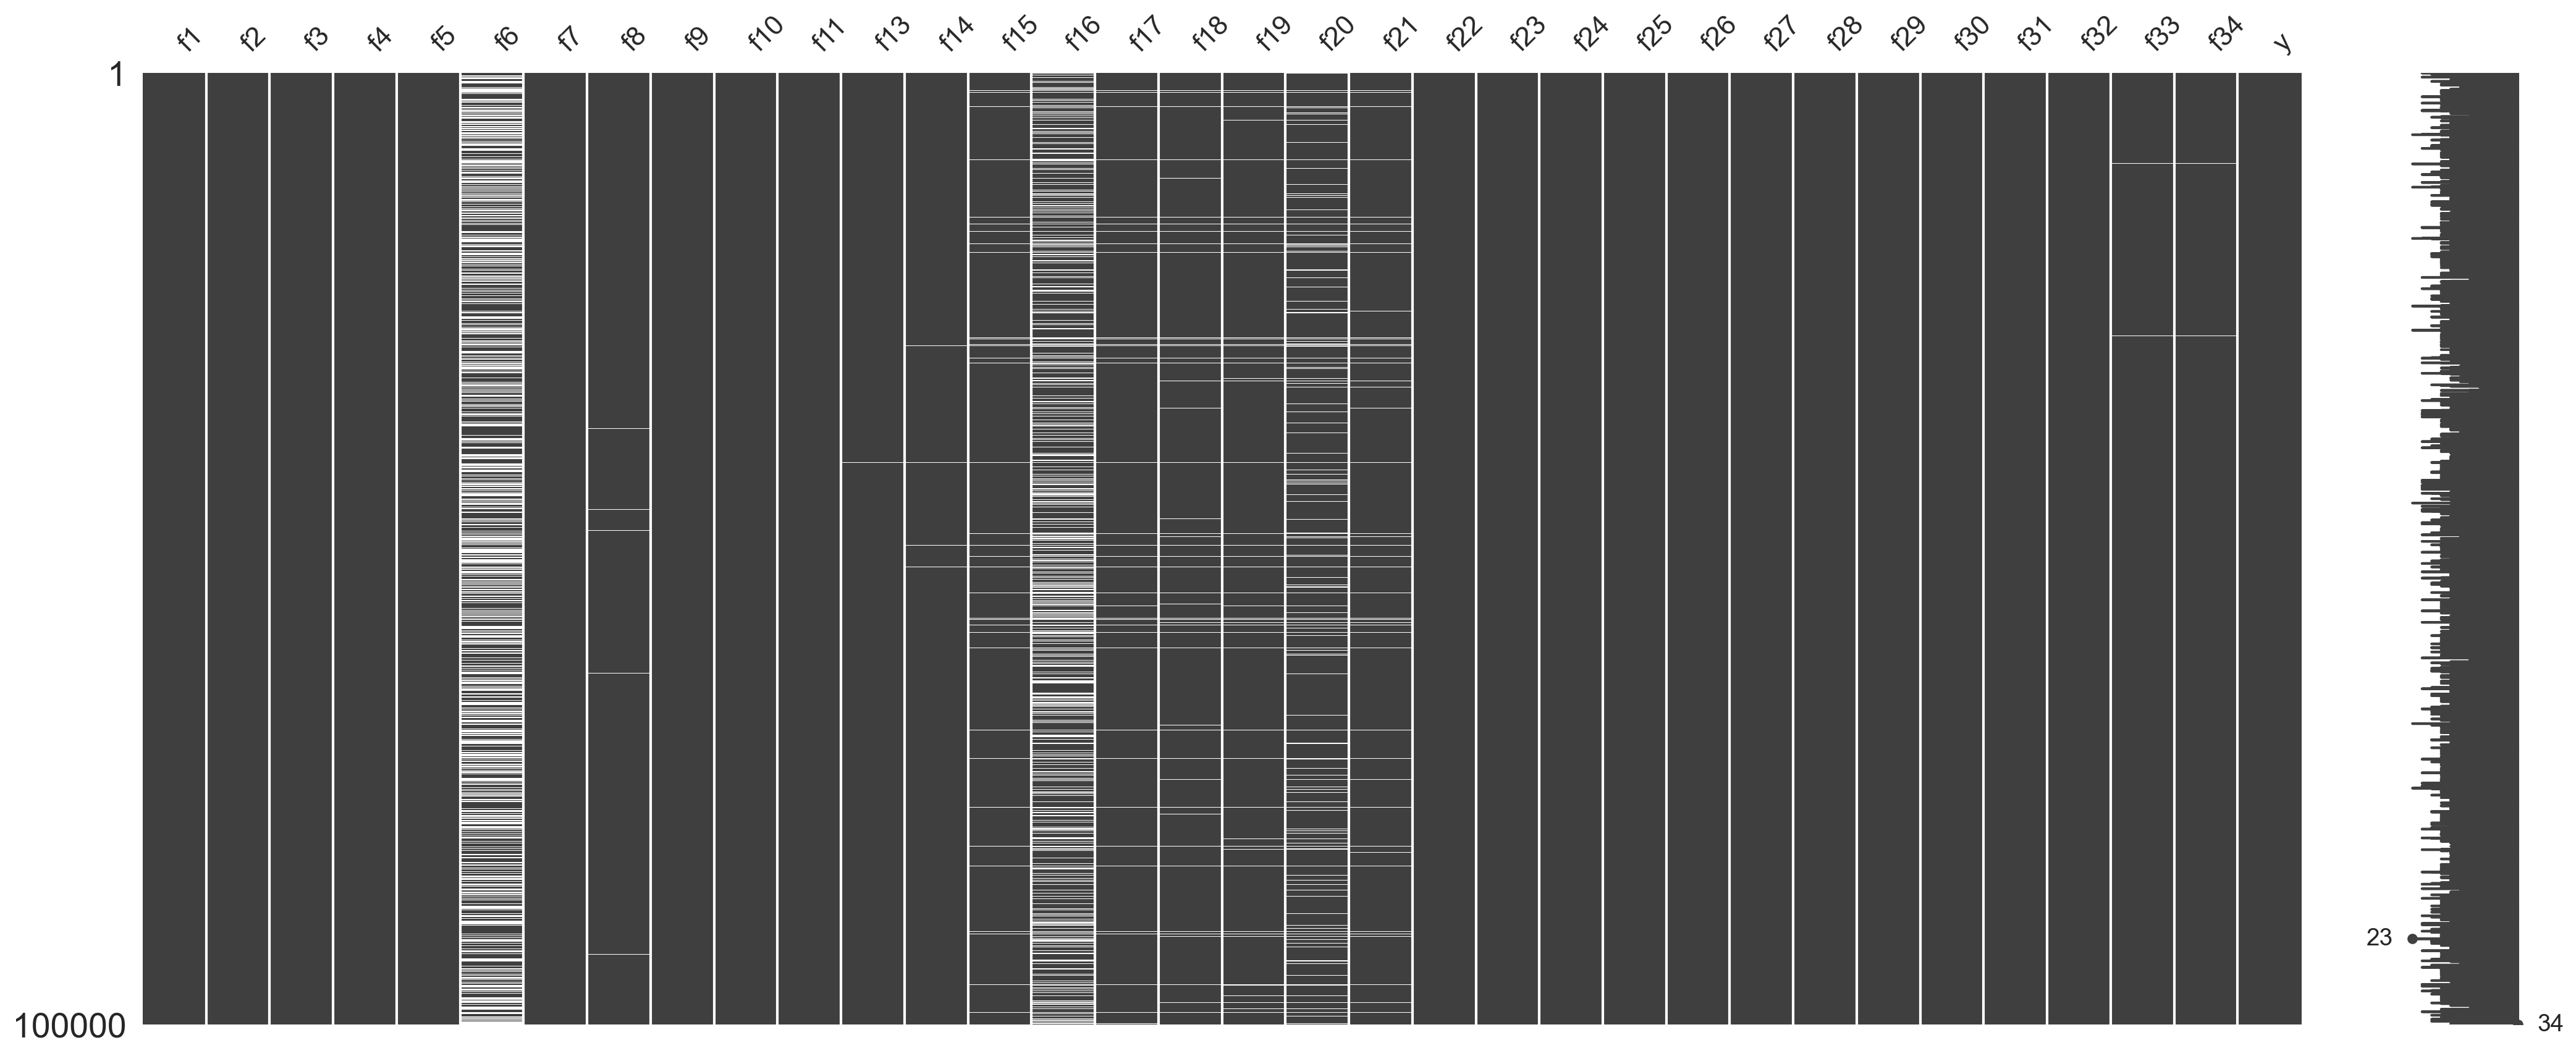

In [19]:
msno.matrix(df)

In [20]:
corr = df.corr(numeric_only=True)

In [24]:
corr.style.background_gradient(cmap='coolwarm')

,f4,f5,f6,f7,f16,f17,f18,f20,f22,f23,f24,f25,f26,f27,f28,f29,f30,f31,f32,y
f4,1.000000,-0.068579,-0.124278,0.064694,-0.475223,-0.193791,-0.088679,0.038415,0.014123,-0.000512,0.002956,0.042447,-0.002010,0.007348,-0.059308,-0.003833,-0.007885,-0.069694,nan,0.060096
f5,-0.068579,1.000000,0.999999,0.004164,-0.028234,0.192879,-0.015869,0.079470,0.006932,-0.009135,0.021918,-0.035844,0.006792,-0.010588,0.009583,-0.028174,0.000965,0.076234,nan,0.054405
f6,-0.124278,0.999999,1.000000,0.001254,0.008264,0.214678,0.004657,0.094798,0.017268,-0.013227,0.022348,-0.009117,0.011867,-0.003744,0.028162,-0.029674,-0.001215,0.054336,nan,0.094716
f7,0.064694,0.004164,0.001254,1.000000,-0.043293,-0.096381,-0.035304,0.005327,-0.029533,-0.004614,-0.012368,0.031011,-0.009552,-0.015199,-0.042704,-0.034223,-0.006274,-0.112517,nan,0.035247
f16,-0.475223,-0.028234,0.008264,-0.043293,1.000000,0.089841,0.239039,-0.049607,0.012448,-0.001394,-0.006543,-0.031100,0.005607,0.006881,0.044925,0.011005,0.005000,0.029756,nan,-0.067102
f17,-0.193791,0.192879,0.214678,-0.096381,0.089841,1.000000,0.031114,-0.022214,0.024777,-0.006077,0.005117,0.036018,-0.001304,0.018891,0.041150,-0.008917,-0.000256,0.042538,nan,0.040717
f18,-0.088679,-0.015869,0.004657,-0.035304,0.239039,0.031114,1.000000,0.011962,0.007207,0.001004,-0.002021,-0.007327,0.007358,-0.000683,0.012844,0.008023,0.002653,0.033947,nan,-0.005352
f20,0.038415,0.079470,0.094798,0.005327,-0.049607,-0.022214,0.011962,1.000000,0.004770,0.002887,0.004487,0.010332,0.003969,0.001480,0.020058,0.004906,0.006748,0.021134,nan,0.036890
f22,0.014123,0.006932,0.017268,-0.029533,0.012448,0.024777,0.007207,0.004770,1.000000,0.005888,0.000145,-0.027799,0.011773,0.051043,0.156997,0.036897,0.008166,0.109905,nan,-0.033037
f23,-0.000512,-0.009135,-0.013227,-0.004614,-0.001394,-0.006077,0.001004,0.002887,0.005888,1.000000,0.012276,-0.006089,0.017258,-0.002032,-0.000649,0.013295,0.699376,-0.005046,nan,-0.003528


In [28]:
missing_counts = df.isnull().sum()/len(df)
missing_counts[missing_counts>0]

f6     0.43842
f8     0.00124
f9     0.00003
f11    0.00024
f13    0.00102
f14    0.00299
f15    0.01509
f16    0.25627
f17    0.01727
f18    0.02232
f19    0.02226
f20    0.07357
f21    0.02173
f33    0.00282
f34    0.00282
dtype: float64

In [26]:
len(df)

100000

#ToDO
handling f6, f16, and f20

f6 has 44% missing value which makes it impossible for us to remove all of the missing values. 